## Model 1: compiled DBQA circuits for Ce$^{3+}$:YAG

`Example_2_DBQA_Ce_YAG.ipynb` applies exact double-bracket rotations to the matrix. Here we compile the algorithm into circuits, as in the Fig. 4 and Quantinuum examples of this repository, and report circuit depth and two-qubit gate count.

The circuit version of DBQA prepares the ground state: starting from a reference state $|\psi_0\rangle$, the double-bracket quantum imaginary-time evolution with a diagonal operator $D_k$ (DB-DOI) appends the reduced group commutator
$$|\psi_{k+1}\rangle = e^{i\sqrt{s_k}D_k}\, e^{i\sqrt{s_k}\hat H}\, e^{-i\sqrt{s_k}D_k}\,|\psi_k\rangle$$
(`GroupCommutatorIteration` with `group_commutator_reduced`), where the evolution under $\hat H$ is conjugated by the circuit prepared so far. $D_k$ is a magnetic field $\sum_i b_i Z_i$, so $e^{isD_k}$ costs no two-qubit gates.

We need an evolution oracle $e^{-it\hat H}$ for the Ce:YAG Hamiltonian. `PauliCompiledHamiltonian` writes $\hat H$ in the Pauli basis and compiles a Trotter-Suzuki step into CNOT ladders, like `XXZ_compilation_line` does for the XXZ chain. We first run DB-DOI with an ideal oracle (`ExactEvolutionHamiltonian`) to obtain the convergence and the number of oracle queries, then build the compiled circuits to count gates and check the effect of the Trotter error.

In [1]:
import os
import logging
import pickle

import numpy as np
import matplotlib.pyplot as plt

from qibo import set_backend
from qibo.config import log

from pycf import cfl
from pycf.import_sljm import ImportSLJM

from qibo_dbqa.utils_crystal_field import *

# PyCF source tree with the bundled matrix-element bases (examples/*/matel)
os.environ.setdefault("PYCF_ROOT", os.path.abspath("../../../pycf"))

set_backend("numpy")
log.setLevel(logging.ERROR)

import sys
import time
from copy import deepcopy

from qibo import gates, hamiltonians
from qibo.symbols import Z
from scipy.linalg import expm

sys.path.append(os.path.abspath("../../src"))
from db_doi.group_commutator_iteration import GroupCommutatorIteration, DoubleBracketRotationApproximationType

[Qibo 0.2.14|INFO|2026-10-15 07:50:28]: Using numpy backend on /CPU:0


In [2]:
parameter_set = "fitted"
coeff = dict(CE_YAG_HU2011[parameter_set], EAVG=0.0)
f1cf = ImportSLJM(pycf_matel_path("f1cf", "ceylf"))
tensors = [f1cf.EAVG] + [getattr(f1cf, name) for name in CE_YAG_TENSORS]

energy_unit = 1000.0
h, n_physical = crystal_field_hamiltonian(tensors, coeff, energy_unit=energy_unit)
h_matrix = h.backend.to_numpy(h.matrix)
energies, vectors = np.linalg.eigh(h_matrix)
tol = 1e-5  # in energy_unit, i.e. 0.01 cm^-1
max_inside, min_between = check_grouping_tolerance(energies, tol)
assert max_inside < tol < min_between
groups = group_levels(energies, tol)
os.makedirs("pdfs_figures", exist_ok=True)
os.makedirs("simulation_results", exist_ok=True)
ground_projector = vectors[:, groups[0]] @ vectors[:, groups[0]].conj().T
first_gap = energies[groups[1][0]] - energies[0]

#### Pauli decomposition

The embedded Hamiltonian is real, so only Pauli strings with an even number of $Y$ appear.

In [3]:
decomposition = pauli_decomposition(h_matrix)
weights = np.bincount([pauli_weight(s) for s in decomposition], minlength=h.nqubits + 1)
print(f"{len(decomposition)} Pauli strings (out of {4**h.nqubits}); number of strings by weight 0..{h.nqubits}: {weights}")
print(f"identity coefficient (global phase only): {decomposition['I'*h.nqubits]:.4f}")
print(f"spectral norm of the traceless part: {np.linalg.norm(h_matrix - decomposition['I'*h.nqubits]*np.eye(16), 2):.3f}")

71 Pauli strings (out of 256); number of strings by weight 0..4: [ 1  6 15 26 23]
identity coefficient (global phase only): 0.4103
spectral norm of the traceless part: 2.872


#### Compiling the evolution oracle

DB-DOI calls the oracle for durations $\sqrt{s}$ with $s\le 0.3$, i.e. up to $t=0.55$. We compare first- and second-order Trotter-Suzuki formulas by the operator-norm error $\|U_{\rm Trotter}(t)-e^{-it(\hat H - c_I)}\|$ (the identity coefficient $c_I$ only gives a global phase). The counts are for the plain CNOT-ladder compilation, without gate cancellations between neighbouring Pauli rotations.

In [4]:
durations = [0.1, 0.3, 0.55]
traceless = h_matrix - decomposition["I"*h.nqubits] * np.eye(2**h.nqubits)
trotter_table = []
print(f"{'order':>5s} {'steps':>5s} " + " ".join(f"{'err(t=%.2f)' % t:>12s}" for t in durations) + f" {'CNOT':>6s} {'depth':>6s}")
for ts_order in [1, 2]:
    for trotter_steps in [1, 2, 4, 8]:
        h_compiled = PauliCompiledHamiltonian(h_matrix, trotter_steps=trotter_steps, ts_order=ts_order)
        errors = [np.linalg.norm(h_compiled.circuit(t).unitary() - expm(-1j * t * traceless), 2) for t in durations]
        circuit = h_compiled.circuit(0.1)
        trotter_table.append(dict(ts_order=ts_order, trotter_steps=trotter_steps, errors=errors, cnot=two_qubit_gate_count(circuit), depth=circuit.depth))
        print(f"{ts_order:5d} {trotter_steps:5d} " + " ".join(f"{e:12.1e}" for e in errors) + f" {two_qubit_gate_count(circuit):6d} {circuit.depth:6d}")

order steps  err(t=0.10)  err(t=0.30)  err(t=0.55)   CNOT  depth


    1     1      1.3e-02      1.1e-01      3.5e-01    272    437


    1     2      6.3e-03      5.5e-02      1.7e-01    544    872


    1     4      3.1e-03      2.7e-02      8.3e-02   1088   1742


    1     8      1.6e-03      1.4e-02      4.2e-02   2176   3482


    2     1      5.1e-04      1.3e-02      7.9e-02    538    867


    2     2      1.3e-04      3.3e-03      1.9e-02   1076   1734


    2     4      3.2e-05      8.3e-04      4.7e-03   2152   3468


    2     8      7.9e-06      2.1e-04      1.2e-03   4304   6936


We use the second-order formula with 4 steps, whose error stays below $5\times10^{-3}$ for every duration used. For comparison, a generic 4-qubit unitary needs at least $\lceil(4^4-3\cdot4-1)/4\rceil = 61$ CNOTs (Shende, Markov and Bullock), so for this small model a direct synthesis of each $e^{-it\hat H}$ would be cheaper than Trotterization; the Trotter compilation is the one that scales to the larger models.

In [5]:
TS_ORDER, TROTTER_STEPS = 2, 4
h_compiled = PauliCompiledHamiltonian(h_matrix, trotter_steps=TROTTER_STEPS, ts_order=TS_ORDER)
oracle_circuit = h_compiled.circuit(0.1)
oracle_cnot, oracle_depth = two_qubit_gate_count(oracle_circuit), oracle_circuit.depth
print(f"one oracle call: {oracle_cnot} CNOTs, depth {oracle_depth}")

one oracle call: 2152 CNOTs, depth 3468


#### Reference state

We start from the computational basis state with the lowest diagonal energy, prepared with $X$ gates. The diagonal of $\hat H_0$ is already close to the spectrum, so this state has a large overlap with the ground doublet.

In [6]:
diagonal = np.real(np.diag(h_matrix))
reference_index = int(np.argmin(diagonal))
reference_circuit = basis_state_circuit(h.nqubits, reference_index)

def state_report(circuit):
    state = h.backend.to_numpy(circuit().state())
    energy = np.real(state.conj() @ h_matrix @ state)
    return dict(
        energy_error=energy_unit * (energy - energies[0]),
        ground_fidelity=np.real(state.conj() @ ground_projector @ state),
        fidelity_witness=1 - (energy - energies[0]) / first_gap,
    )

print(f"reference state |{format(reference_index, '04b')}>:", state_report(reference_circuit))

reference state |0101>: {'energy_error': 19.671982556060286, 'ground_fidelity': 0.9650262569600042, 'fidelity_witness': 0.9388831590864223}


#### DB-DOI with an ideal oracle

At each step we choose the magnetic field $D_k=\sum_i b_i Z_i$ among all sign patterns $b_i=\pm1$ and the step $s_k$ on a grid, minimising the energy (the loss of `GroupCommutatorIteration`). The number of oracle queries grows by about a factor 3 per step, because the evolution under $\hat H_k$ is the evolution under $\hat H$ conjugated by the circuit prepared so far.

In [7]:
NSTEPS_DOI = 7
step_grid = np.linspace(1e-3, 0.3, 20)
magnetic_fields = [np.array([1 - 2 * b for b in bits], dtype=float) for bits in np.ndindex(*(2,) * h.nqubits)]
d_candidates = [hamiltonians.SymbolicHamiltonian(sum(b * Z(q) for q, b in enumerate(field)), nqubits=h.nqubits) for field in magnetic_fields]

def oracle_queries(circuit):
    return sum(1 for g in circuit.queue if isinstance(g, gates.Unitary) and len(g.qubits) == h.nqubits)

gci = GroupCommutatorIteration(
    h=ExactEvolutionHamiltonian(h_matrix),
    preparation_circuit=deepcopy(reference_circuit),
    double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
)
doi_history = [dict(state_report(gci.preparation_circuit), queries=0, step=None, field=None)]
for k in range(NSTEPS_DOI):
    start = time.time()
    best = None
    for j, d in enumerate(d_candidates):
        s, loss, _, _ = gci.choose_step(d, step_grid=step_grid)
        if best is None or loss < best[1]:
            best = (s, loss, j)
    gci(best[0], d_candidates[best[2]])
    doi_history.append(dict(state_report(gci.preparation_circuit), queries=oracle_queries(gci.preparation_circuit), step=best[0], field=magnetic_fields[best[2]]))
    r = doi_history[-1]
    print(f"k={k+1}: s={r['step']:.3f}, b={r['field'].astype(int)}, dE={r['energy_error']:.3f} cm^-1, 1-F={1 - r['ground_fidelity']:.2e}, oracle queries={r['queries']}, {time.time()-start:.0f}s")

k=1: s=0.080, b=[1 1 1 1], dE=11.247 cm^-1, 1-F=2.83e-02, oracle queries=1, 3s


k=2: s=0.190, b=[ 1  1  1 -1], dE=8.377 cm^-1, 1-F=2.18e-02, oracle queries=4, 4s


k=3: s=0.111, b=[-1  1  1  1], dE=6.529 cm^-1, 1-F=1.90e-02, oracle queries=13, 6s


k=4: s=0.237, b=[ 1  1  1 -1], dE=5.044 cm^-1, 1-F=1.44e-02, oracle queries=40, 11s


k=5: s=0.237, b=[ 1  1  1 -1], dE=3.834 cm^-1, 1-F=1.05e-02, oracle queries=121, 27s


k=6: s=0.300, b=[-1  1  1 -1], dE=2.950 cm^-1, 1-F=7.75e-03, oracle queries=364, 96s


k=7: s=0.095, b=[ 1  1  1 -1], dE=2.283 cm^-1, 1-F=6.68e-03, oracle queries=1093, 243s


#### Compiled circuits

We replay the same sequence of steps and magnetic fields with the compiled oracle and build the circuits explicitly for the first steps. All two-qubit gates come from the oracle calls, so for any step the CNOT count is the number of oracle queries times the CNOTs per call, which we check on the explicit circuits. The depth is reported for the circuits that are built explicitly.

In [8]:
NSTEPS_COMPILED = 3
gci_compiled = GroupCommutatorIteration(
    h=deepcopy(h_compiled),
    preparation_circuit=deepcopy(reference_circuit),
    double_bracket_rotation_approximation_type=DoubleBracketRotationApproximationType.group_commutator_reduced,
)
compiled_history = [dict(state_report(gci_compiled.preparation_circuit), cnot=0, depth=reference_circuit.depth)]
for k in range(NSTEPS_COMPILED):
    start = time.time()
    r = doi_history[k + 1]
    gci_compiled(r["step"], d_candidates[[np.array_equal(r["field"], f) for f in magnetic_fields].index(True)])
    circuit = gci_compiled.preparation_circuit
    compiled_history.append(dict(state_report(circuit), cnot=two_qubit_gate_count(circuit), depth=circuit.depth))
    c = compiled_history[-1]
    print(f"k={k+1}: CNOT={c['cnot']} (= {r['queries']} queries x {oracle_cnot}: {c['cnot'] == r['queries'] * oracle_cnot}), depth={c['depth']}, "
          f"dE={c['energy_error']:.3f} cm^-1 (ideal {r['energy_error']:.3f}), 1-F={1 - c['ground_fidelity']:.2e} (ideal {1 - r['ground_fidelity']:.2e}), {time.time()-start:.0f}s")

k=1: CNOT=2152 (= 1 queries x 2152: True), depth=3475, dE=11.244 cm^-1 (ideal 11.247), 1-F=2.83e-02 (ideal 2.83e-02), 0s


k=2: CNOT=8608 (= 4 queries x 2152: True), depth=13897, dE=8.377 cm^-1 (ideal 8.377), 1-F=2.18e-02 (ideal 2.18e-02), 1s


k=3: CNOT=27976 (= 13 queries x 2152: True), depth=45163, dE=6.524 cm^-1 (ideal 6.529), 1-F=1.90e-02 (ideal 1.90e-02), 4s


In [9]:
print(f"{'k':>2s} {'dE (cm^-1)':>11s} {'1-F':>9s} {'witness':>8s} {'queries':>8s} {'CNOT':>9s} {'depth':>9s}")
for k, r in enumerate(doi_history):
    cnot = r["queries"] * oracle_cnot
    depth = compiled_history[k]["depth"] if k < len(compiled_history) else None
    depth_text = f"{depth:9d}" if depth is not None else f"{'not built':>9s}"
    print(f"{k:2d} {r['energy_error']:11.3f} {1 - r['ground_fidelity']:9.2e} {r['fidelity_witness']:8.4f} {r['queries']:8d} {cnot:9d} {depth_text}")

 k  dE (cm^-1)       1-F  witness  queries      CNOT     depth
 0      19.672  3.50e-02   0.9389        0         0         1
 1      11.247  2.83e-02   0.9651        1      2152      3475
 2       8.377  2.18e-02   0.9740        4      8608     13897
 3       6.529  1.90e-02   0.9797       13     27976     45163
 4       5.044  1.44e-02   0.9843       40     86080 not built
 5       3.834  1.05e-02   0.9881      121    260392 not built
 6       2.950  7.75e-03   0.9908      364    783328 not built
 7       2.283  6.68e-03   0.9929     1093   2352136 not built


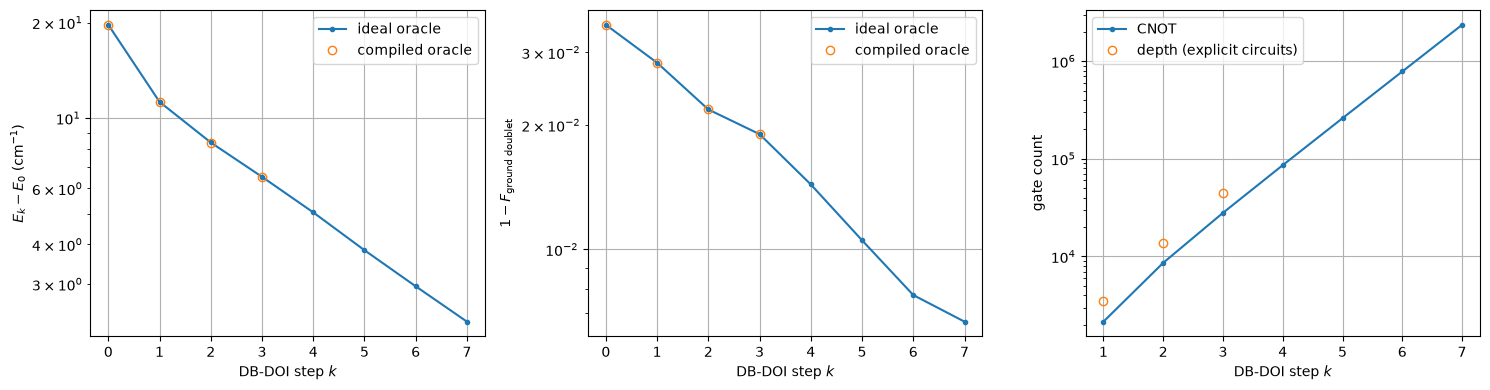

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ks = np.arange(len(doi_history))
axes[0].semilogy(ks, [r["energy_error"] for r in doi_history], ".-", label="ideal oracle")
axes[0].semilogy(np.arange(len(compiled_history)), [r["energy_error"] for r in compiled_history], "o", mfc="none", label="compiled oracle")
axes[0].set_ylabel(r"$E_k - E_0$ (cm$^{-1}$)")
axes[1].semilogy(ks, [1 - r["ground_fidelity"] for r in doi_history], ".-", label="ideal oracle")
axes[1].semilogy(np.arange(len(compiled_history)), [1 - r["ground_fidelity"] for r in compiled_history], "o", mfc="none", label="compiled oracle")
axes[1].set_ylabel(r"$1-F_{\rm ground\ doublet}$")
axes[2].semilogy(ks[1:], [r["queries"] * oracle_cnot for r in doi_history[1:]], ".-", label="CNOT")
axes[2].semilogy(np.arange(1, len(compiled_history)), [r["depth"] for r in compiled_history[1:]], "o", mfc="none", label="depth (explicit circuits)")
axes[2].set_ylabel("gate count")
for ax in axes:
    ax.set_xlabel("DB-DOI step $k$"); ax.grid(True); ax.legend()
plt.tight_layout()
plt.savefig("pdfs_figures/Ce_YAG_compiled_DB_DOI.pdf", bbox_inches="tight")
plt.show()

#### Saving the data

In [11]:
with open(f"simulation_results/Ce_YAG_{parameter_set}_compiled_DB_DOI_L_{h.nqubits}.pickle", "wb") as file:
    pickle.dump(
        dict(
            parameter_set=parameter_set,
            pauli_decomposition=decomposition,
            trotter_table=trotter_table,
            ts_order=TS_ORDER,
            trotter_steps=TROTTER_STEPS,
            oracle_cnot=oracle_cnot,
            oracle_depth=oracle_depth,
            reference_index=reference_index,
            doi_history=doi_history,
            compiled_history=compiled_history,
        ),
        file,
    )